# Assignment 

## Hardware Characterization and Region Recommendation

### Background

Modern hardware systems are not perfectly uniform.

Different regions of a device may exhibit different operational characteristics due to calibration, reliability, connectivity, and other factors.

You are provided with:

- a calibration snapshot
- topology information

Your task is to analyze the provided information and make a recommendation.

---

### Files Provided

- ibm_kingston_calibrations.csv
- ibm_kingston_topology_complete.json

---

### Deliverables

Your notebook must contain:

1. Dataset analysis
2. Methodology
3. One recommended 16-qubit region
4. One recommended 32-qubit region
5. Written responses to all questions

---
### Notes

The provided data contains sufficient information to make a reasonable recommendation.

You may use any information available in the provided files.

Document your analysis in the notebook.

## Instructions

You may use:

- Python
- NumPy
- Pandas
- NetworkX
- SciPy
- Any standard open-source package

You may add additional cells as required.

The final notebook should execute from top to bottom without modification.

In [1]:
import json
import glob
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 6)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Locate the uploaded calibration snapshot and topology automatically.
# This makes the notebook tolerant of small filename differences such as "(1)" or "(2)".
cal_files = glob.glob("*calibrations*.xls") + glob.glob("*calibrations*.csv")
topo_files = glob.glob("*topology*.json")

if not cal_files:
    raise FileNotFoundError("Calibration file not found in the current folder.")
if not topo_files:
    raise FileNotFoundError("Topology JSON file not found in the current folder.")

CALIBRATION_FILE = cal_files[0]
TOPOLOGY_FILE = topo_files[0]

# The provided .xls file is UTF-8 CSV text rather than a binary Excel workbook.
cal = pd.read_csv(CALIBRATION_FILE)
with open(TOPOLOGY_FILE, "r", encoding="utf-8") as f:
    topology = json.load(f)

print("Calibration file:", CALIBRATION_FILE)
print("Topology file:", TOPOLOGY_FILE)
print("Calibration shape:", cal.shape)
print("Topology qubits:", topology["num_qubits"])

Calibration file: calibrations.xls
Topology file: topology.json
Calibration shape: (156, 19)
Topology qubits: 156


# Part 1

## Initial Dataset Analysis

Perform an initial analysis of the calibration snapshot.



In [3]:
# ---------- Part 1: Initial dataset analysis ----------
print("Calibration columns:")
display(pd.DataFrame({"Column": cal.columns}))

print("\nFirst five rows:")
display(cal.head())

print("\nMissing values:")
missing_table = cal.isna().sum().to_frame("Missing values")
display(missing_table[missing_table["Missing values"] > 0])

# Numeric summary of the main qubit-level calibration metrics
main_metrics = [
    "T1 (us)", "T2 (us)", "Readout assignment error",
    "ID error", "RX error", "√x (sx) error", "Pauli-X error"
]
print("\nSummary statistics:")
display(cal[main_metrics].describe().T)

# Parse strings such as "2:0.00096;0:0.00101" into neighbour -> value pairs.
def parse_neighbour_values(value):
    if pd.isna(value) or str(value).strip() == "":
        return {}
    result = {}
    for part in str(value).split(";"):
        if ":" not in part:
            continue
        neighbour, metric_value = part.split(":", 1)
        try:
            result[int(neighbour)] = float(metric_value)
        except ValueError:
            pass
    return result

edge_records = {}
for _, row in cal.iterrows():
    q = int(row["Qubit"])
    for name, key in [("CZ error", "cz"), ("RZZ error", "rzz")]:
        for neighbour, value in parse_neighbour_values(row[name]).items():
            edge = tuple(sorted((q, int(neighbour))))
            edge_records.setdefault(edge, {}).setdefault(key, []).append(value)

edge_df = pd.DataFrame([
    {
        "u": edge[0],
        "v": edge[1],
        "CZ error": np.mean(values.get("cz", [np.nan])),
        "RZZ error": np.mean(values.get("rzz", [np.nan])),
    }
    for edge, values in edge_records.items()
])
edge_df["edge"] = list(zip(edge_df["u"], edge_df["v"]))

print("\nTwo-qubit edge summary:")
display(edge_df[["CZ error", "RZZ error"]].describe(percentiles=[0.5, 0.9, 0.99]))

# Identify obvious data-quality issues
bad_readout = cal.loc[cal["Readout assignment error"] > 0.10, "Qubit"].astype(int).tolist()
low_t2 = cal.loc[cal["T2 (us)"] < 30, "Qubit"].astype(int).tolist()

print("\nQubits with readout error > 0.10:", bad_readout)
print("Qubits with T2 < 30 us:", low_t2)
print("Worst measured CZ edge:")
display(edge_df.loc[[edge_df["CZ error"].idxmax()]])

Calibration columns:


,Column
0,Qubit
1,T1 (us)
2,T2 (us)
3,Readout assignment error
4,Prob meas0 prep1
5,Prob meas1 prep0
6,Readout length (ns)
7,ID error
8,Single-qubit gate length (ns)
9,RX error



First five rows:


,Qubit,T1 (us),T2 (us),Readout assignment error,Prob meas0 prep1,Prob meas1 prep0,Readout length (ns),ID error,Single-qubit gate length (ns),RX error,Z-axis rotation (rz) error,√x (sx) error,Pauli-X error,CZ error,Gate length (ns),RZZ error,MEASURE error,MEASURE_2 error,Operational
0,0,290.800821,298.140732,0.011475,0.014404,0.008545,2280,0.000205,32,0.000205,0,0.000205,0.000205,1:0.0010167457696165227,1:68,1:0.0010602119472144789,0.011475,0.016602,Yes
1,1,372.822654,437.021834,0.164795,0.100342,0.229248,2280,0.000181,32,0.000181,0,0.000181,0.000181,2:0.0009609959626648845;0:0.0010167457696165227,2:68;0:68,2:0.0009016463575797495;0:0.0010602119472144789,0.164795,0.081055,Yes
2,2,305.112602,107.784842,0.008057,0.010742,0.005371,2280,0.000100,32,0.000100,0,0.000100,0.000100,1:0.0009609959626648845;3:0.0012523142615088745,1:68;3:68,1:0.0009016463575797495;3:0.000930022916350165,0.008057,0.008057,Yes
3,3,354.894616,483.530444,0.008301,0.011475,0.005127,2280,0.000243,32,0.000243,0,0.000243,0.000243,16:0.0012413347520312812;2:0.00125231426150887...,16:68;2:68;4:68,16:0.001184823243668115;2:0.000930022916350165...,0.008301,0.007324,Yes
4,4,316.778855,53.238112,0.022339,0.018799,0.025879,2280,0.000282,32,0.000282,0,0.000282,0.000282,3:0.002007963045889627;5:0.002521856056860644,3:68;5:68,3:0.0018174791538967394;5:0.0026275206583171173,0.022339,0.013916,Yes



Missing values:


,Missing values
T1 (us),1
T2 (us),1
ID error,3
RX error,3
√x (sx) error,3
Pauli-X error,3
CZ error,3
RZZ error,4


... (2 outputs left out)


Two-qubit edge summary:


,CZ error,RZZ error
count,170.000000,167.000000
mean,0.003536,0.003255
std,0.007059,0.006675
min,0.000891,0.000891
50%,0.001839,0.001829
90%,0.005448,0.004269
99%,0.042549,0.038338
max,0.060314,0.056313



Qubits with readout error > 0.10: [1, 96, 102, 113, 127, 131, 146]
Qubits with T2 < 30 us: [10, 25, 37, 48, 78, 86, 88, 114, 115, 123, 137, 139]
Worst measured CZ edge:


,u,v,CZ error,RZZ error,edge
97,84,85,0.060314,0.056313,"(84, 85)"


## Observations

The snapshot contains **156 qubit records and 19 columns**. The most informative qubit-level quantities are T1, T2, readout assignment error and single-qubit gate error. Several columns are duplicates or constants, so they were not allowed to dominate the scoring.

The CZ edge errors are strongly skewed: a small number of couplers are much worse than the median. Missing calibration values are also important because an apparently connected region may contain an edge whose two-qubit reliability is unknown. Therefore, the final search uses a **hard exclusion for uncalibrated internal CZ edges**.

The data also contains a small number of severe readout/coherence outliers. These are screened out before the final search so that an otherwise good average cannot hide an obviously unreliable bottleneck.

# Part 2

## Hardware Representation

Construct any representation(s) you believe are useful for this assignment.

Explain any design choices you make.

In [4]:
# ---------- Part 2: Hardware representation ----------
G = nx.Graph()
G.add_nodes_from(range(topology["num_qubits"]))
undirected_edges = [tuple(sorted(e)) for e in topology["coupling_map_undirected"]]
G.add_edges_from(undirected_edges)

print("Nodes:", G.number_of_nodes())
print("Undirected edges:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))
print("Degree range:", min(dict(G.degree()).values()), "to", max(dict(G.degree()).values()))

topology_edges = set(undirected_edges)
calibrated_edges = set(edge_df["edge"])
missing_edge_calibration = sorted(topology_edges - calibrated_edges)

print("\nTopology edges without CZ calibration:", missing_edge_calibration)

degree_counts = pd.Series(dict(G.degree())).value_counts().sort_index()
display(pd.DataFrame({"Degree": degree_counts.index, "Number of qubits": degree_counts.values}))

# A graph is the natural representation: nodes are physical qubits and edges are
# physical two-qubit couplings.
print("\nThe full hardware graph is connected:", nx.is_connected(G))

Nodes: 156
Undirected edges: 176
Connected components: 1
Degree range: 1 to 3

Topology edges without CZ calibration: [(111, 112), (112, 113), (120, 121), (130, 131), (145, 146), (146, 147)]


,Degree,Number of qubits
0,1,8
1,2,100
2,3,48



The full hardware graph is connected: True


## Representation Notes  (few words )

IBM Kingston is represented as an **undirected graph**: physical qubits are nodes and hardware couplings are edges. A recommended region must be a connected induced subgraph of this graph.

# Part 3

Identify one candidate 16-qubit region and one candidate 32-qubit region.

You may use any information available in the provided files.

Provide one recommended 16-qubit region and one recommended 32-qubit region.

Document your methodology.

In [5]:
# ---------- Part 3: Bottleneck-aware connected-region search ----------

qdf = cal.set_index("Qubit").copy()

def percentile_quality(series, higher_is_better=True):
    values = pd.to_numeric(series, errors="coerce")
    rank = values.rank(pct=True, method="average")
    if higher_is_better:
        return rank
    # Lower error should receive higher quality.
    return 1 - rank + 1 / max(values.notna().sum(), 1)

# Rank/percentile normalization is robust to the heavy-tailed calibration data.
qdf["readout_quality"] = percentile_quality(qdf["Readout assignment error"], False)
qdf["single_gate_quality"] = percentile_quality(qdf["ID error"], False)

# Cap extremely high coherence before ranking so excess coherence does not dominate.
for metric, new_name in [("T1 (us)", "t1_quality"), ("T2 (us)", "t2_quality")]:
    values = pd.to_numeric(qdf[metric], errors="coerce")
    qdf[new_name] = percentile_quality(values.clip(upper=values.quantile(0.95)), True)

# Readout and T2 receive slightly more emphasis because they show meaningful
# variation and directly affect measurement/coherence reliability.
qdf["qubit_score"] = (
    0.35 * qdf["readout_quality"]
    + 0.15 * qdf["single_gate_quality"]
    + 0.20 * qdf["t1_quality"]
    + 0.30 * qdf["t2_quality"]
)

# Edge quality: CZ is the primary two-qubit metric; RZZ is secondary when available.
edge_df["cz_quality"] = percentile_quality(edge_df["CZ error"], False)
edge_df["rzz_quality"] = percentile_quality(edge_df["RZZ error"], False)
edge_df["edge_score"] = np.where(
    edge_df["rzz_quality"].notna(),
    0.85 * edge_df["cz_quality"] + 0.15 * edge_df["rzz_quality"],
    edge_df["cz_quality"],
)

edge_score = {
    tuple(sorted((int(r["u"]), int(r["v"])))): float(r["edge_score"])
    for _, r in edge_df.iterrows()
    if np.isfinite(r["edge_score"])
}

# Data availability screen.
valid_nodes = set(qdf.index[
    qdf[["T1 (us)", "T2 (us)", "Readout assignment error", "ID error"]].notna().all(axis=1)
])

# Severe outlier screen used only before final candidate generation.
severe_outliers = set(qdf.index[
    (qdf["Readout assignment error"] > 0.10) | (qdf["T2 (us)"] < 30)
])

H = G.copy()
H.remove_nodes_from(set(H.nodes) - valid_nodes)
H.remove_nodes_from(severe_outliers)
H.remove_edges_from([e for e in list(H.edges) if tuple(sorted(e)) not in edge_score])

print("Search graph nodes:", H.number_of_nodes())
print("Search graph edges:", H.number_of_edges())
print("Connected components in search graph:", nx.number_connected_components(H))
print("Excluded severe outliers:", sorted(severe_outliers))

def region_metrics(region):
    region = set(region)
    SG = G.subgraph(region)
    internal_edges = [tuple(sorted(e)) for e in SG.edges()]
    calibrated = [e for e in internal_edges if e in edge_score]

    if len(region) == 0:
        raise ValueError("Empty region")

    node_scores = qdf.loc[list(region), "qubit_score"].astype(float).to_numpy()
    edge_scores = np.array([edge_score[e] for e in calibrated], dtype=float)

    qubit_quality = float(np.mean(node_scores))
    edge_quality = float(np.mean(edge_scores)) if len(edge_scores) else 0.0

    combined = np.concatenate([node_scores, edge_scores]) if len(edge_scores) else node_scores
    robustness = float(
        0.30 * np.min(node_scores)
        + 0.40 * (np.min(edge_scores) if len(edge_scores) else 0.0)
        + 0.30 * np.percentile(combined, 10)
    )

    degrees = np.array([SG.degree(q) for q in region], dtype=float)
    connectivity = float(
        0.70 * np.mean(degrees) / 3.0
        + 0.30 * np.mean(degrees >= 2)
    )

    composite = float(
        0.35 * edge_quality
        + 0.25 * qubit_quality
        + 0.25 * robustness
        + 0.15 * connectivity
    )

    return {
        "size": len(region),
        "connected": nx.is_connected(SG),
        "internal_edges": len(internal_edges),
        "has_uncalibrated_edge": len(calibrated) != len(internal_edges),
        "qubit_quality": qubit_quality,
        "edge_quality": edge_quality,
        "robustness": robustness,
        "connectivity": connectivity,
        "composite": composite,
        "worst_qubit": float(np.min(node_scores)),
        "worst_edge": float(np.min(edge_scores)) if len(edge_scores) else 0.0,
        "p10_quality": float(np.percentile(combined, 10)),
    }

def grow_connected_region(size, rng, temperature):
    components = [c for c in nx.connected_components(H) if len(c) >= size]
    component = list(max(components, key=len))
    region = {int(rng.choice(component))}

    while len(region) < size:
        frontier = set()
        for u in region:
            frontier.update(set(H.neighbors(u)) - region)
        if not frontier:
            return None

        candidates = list(frontier)
        values = []
        for v in candidates:
            incident = [
                edge_score[tuple(sorted((v, u)))]
                for u in region
                if H.has_edge(v, u)
            ]
            values.append(
                0.55 * float(qdf.at[v, "qubit_score"])
                + 0.45 * float(np.mean(incident))
            )

        values = np.asarray(values, dtype=float)
        scaled = (values - values.max()) / max(temperature, 1e-6)
        probabilities = np.exp(scaled)
        probabilities /= probabilities.sum()
        region.add(int(rng.choice(candidates, p=probabilities)))

    metrics = region_metrics(region)
    if metrics["has_uncalibrated_edge"]:
        return None
    return frozenset(region)

def search_candidates(size, trials, seed):
    local_rng = np.random.default_rng(seed)
    seen = set()

    for _ in range(trials):
        region = grow_connected_region(
            size, local_rng, float(local_rng.uniform(0.05, 0.35))
        )
        if region is not None:
            seen.add(region)

    rows = []
    for region in seen:
        row = region_metrics(region)
        row["region"] = tuple(sorted(region))
        rows.append(row)

    return (
        pd.DataFrame(rows)
        .sort_values("composite", ascending=False)
        .reset_index(drop=True)
    )

# Multiple stochastic connected-growth runs provide diverse candidates while
# keeping the search reproducible through fixed random seeds.
candidates16 = search_candidates(16, trials=6000, seed=11)
candidates32 = search_candidates(32, trials=3000, seed=12)

print("Top 5 candidate 16-qubit regions:")
display(candidates16.head(5)[
    ["region", "composite", "qubit_quality", "edge_quality",
     "robustness", "connectivity", "internal_edges"]
])

print("Top 5 candidate 32-qubit regions:")
display(candidates32.head(5)[
    ["region", "composite", "qubit_quality", "edge_quality",
     "robustness", "connectivity", "internal_edges"]
])

FINAL16 = tuple(candidates16.iloc[0]["region"])
FINAL32 = tuple(candidates32.iloc[0]["region"])

print("Selected 16-qubit region:", FINAL16)
print("Selected 32-qubit region:", FINAL32)

Search graph nodes:

 136
Search graph edges: 135
Connected components in search graph: 7
Excluded severe outliers: [1, 10, 25, 37, 48, 78, 86, 88, 96, 102, 113, 114, 115, 123, 127, 131, 137, 139, 146]


Top 5 candidate 16-qubit regions:


,region,composite,qubit_quality,edge_quality,robustness,connectivity,internal_edges
0,"(87, 97, 103, 104, 105, 106, 107, 108, 109, 11...",0.547579,0.556872,0.684846,0.288410,0.64375,15
1,"(87, 91, 97, 98, 103, 104, 105, 106, 107, 108,...",0.542937,0.536254,0.657918,0.316908,0.66250,15
2,"(97, 103, 104, 105, 106, 107, 108, 109, 110, 1...",0.542557,0.572010,0.658246,0.290425,0.64375,15
3,"(91, 97, 98, 103, 104, 105, 106, 107, 108, 109...",0.542457,0.551567,0.653024,0.317779,0.64375,15
4,"(87, 97, 98, 103, 104, 105, 106, 107, 108, 109...",0.542214,0.542385,0.659509,0.316908,0.64375,15


Top 5 candidate 32-qubit regions:


,region,composite,qubit_quality,edge_quality,robustness,connectivity,internal_edges
0,"(39, 52, 53, 54, 55, 59, 73, 74, 75, 79, 87, 8...",0.524276,0.528938,0.653315,0.241653,0.686458,31
1,"(39, 53, 54, 55, 59, 73, 74, 75, 79, 87, 90, 9...",0.523658,0.547085,0.641485,0.243218,0.677083,31
2,"(39, 53, 54, 55, 59, 73, 74, 75, 79, 89, 90, 9...",0.522317,0.550815,0.633434,0.245393,0.677083,31
3,"(39, 52, 53, 54, 55, 59, 73, 74, 75, 79, 87, 9...",0.521719,0.536605,0.645682,0.240068,0.677083,31
4,"(54, 55, 59, 73, 74, 75, 79, 87, 90, 91, 92, 9...",0.521419,0.553002,0.629308,0.245393,0.677083,31


Selected 16-qubit region: (87, 97, 103, 104, 105, 106, 107, 108, 109, 117, 118, 124, 125, 126, 128, 129)
Selected 32-qubit region: (39, 52, 53, 54, 55, 59, 73, 74, 75, 79, 87, 89, 90, 91, 92, 93, 94, 95, 97, 98, 103, 104, 105, 106, 107, 108, 109, 110, 111, 117, 125, 126)


## Methodology in brief

### Bottleneck-Aware Connected-Region Search

1. **Clean and screen the data:** missing calibration records and uncalibrated CZ edges are not silently ignored. Severe readout/coherence outliers are excluded from the final search.
2. **Normalize robustly:** percentile/rank normalization is used because the error distributions are heavy-tailed. Lower errors are reversed so that a larger quality score is always better.
3. **Score qubits:** readout error, single-qubit error, T1 and T2 are combined.
4. **Score couplers:** CZ error is the main two-qubit signal, with RZZ used as a secondary signal where available.
5. **Penalize bottlenecks:** the robustness component includes the worst qubit, worst internal edge and the 10th-percentile quality instead of using only an average.
6. **Search only connected regions:** regions are grown through physical neighbours and many randomized searches are compared.
7. **Composite score:** edge quality 35%, qubit quality 25%, robustness 25%, connectivity 15%.

This approach prefers a region that is consistently reliable rather than one with an attractive average but a serious weak link.

# Part 4

## Recommended 16-Qubit Region

Provide one 16-qubit region that you would recommend.

Include supporting rationale.

Recommended 16-qubit region:
[87, 97, 103, 104, 105, 106, 107, 108, 109, 117, 118, 124, 125, 126, 128, 129]

Validation:
Number of qubits: 16
Connected: True
Uncalibrated internal edges: False
Internal edges: 15


,16-qubit value
internal_edges,15.000000
qubit_quality,0.556872
edge_quality,0.684846
robustness,0.288410
connectivity,0.643750
composite,0.547579
worst_qubit,0.331156
worst_edge,0.182066
p10_quality,0.387457


,Selected region,Random baseline mean
Composite,0.547579,0.455737
Qubit quality,0.556872,0.502537
Edge quality,0.684846,0.521810
Robustness,0.288410,0.198966


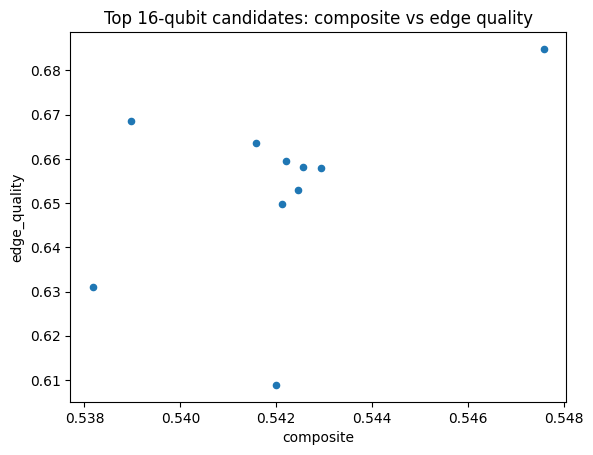

In [6]:
# ---------- Part 4: Recommended 16-qubit region ----------
metrics16 = region_metrics(FINAL16)
sub16 = G.subgraph(FINAL16)

print("Recommended 16-qubit region:")
print(list(FINAL16))
print("\nValidation:")
print("Number of qubits:", len(FINAL16))
print("Connected:", nx.is_connected(sub16))
print("Uncalibrated internal edges:", metrics16["has_uncalibrated_edge"])
print("Internal edges:", metrics16["internal_edges"])

summary16 = pd.DataFrame([metrics16]).drop(columns=["size", "connected", "has_uncalibrated_edge"])
display(summary16.T.rename(columns={0: "16-qubit value"}))

# Compare with random connected regions of the same size.
def random_connected_baseline(size, samples, seed):
    local_rng = np.random.default_rng(seed)
    rows = []
    attempts = 0
    while len(rows) < samples and attempts < samples * 30:
        attempts += 1
        components = [c for c in nx.connected_components(H) if len(c) >= size]
        component = list(max(components, key=len))
        region = {int(local_rng.choice(component))}
        while len(region) < size:
            frontier = set()
            for u in region:
                frontier.update(set(H.neighbors(u)) - region)
            if not frontier:
                break
            region.add(int(local_rng.choice(list(frontier))))
        if len(region) == size:
            m = region_metrics(region)
            if m["connected"] and not m["has_uncalibrated_edge"]:
                rows.append(m)
    return pd.DataFrame(rows)

baseline16 = random_connected_baseline(16, 300, 101)
comparison16 = pd.DataFrame({
    "Selected region": [
        metrics16["composite"], metrics16["qubit_quality"],
        metrics16["edge_quality"], metrics16["robustness"]
    ],
    "Random baseline mean": [
        baseline16["composite"].mean(), baseline16["qubit_quality"].mean(),
        baseline16["edge_quality"].mean(), baseline16["robustness"].mean()
    ]
}, index=["Composite", "Qubit quality", "Edge quality", "Robustness"])
display(comparison16)

ax = candidates16.head(10).plot(
    x="composite", y="edge_quality", kind="scatter",
    title="Top 16-qubit candidates: composite vs edge quality"
)
plt.show()

# Part 5

## Recommended 32-Qubit Region

Provide one 32-qubit region that you would recommend.

Include supporting rationale.

Recommended 32-qubit region:
[39, 52, 53, 54, 55, 59, 73, 74, 75, 79, 87, 89, 90, 91, 92, 93, 94, 95, 97, 98, 103, 104, 105, 106, 107, 108, 109, 110, 111, 117, 125, 126]

Validation:
Number of qubits: 32
Connected: True
Uncalibrated internal edges: False
Internal edges: 31


,32-qubit value
internal_edges,31.000000
qubit_quality,0.528938
edge_quality,0.653315
robustness,0.241653
connectivity,0.686458
composite,0.524276
worst_qubit,0.240835
worst_edge,0.174132
p10_quality,0.332499


,Selected region,Random baseline mean
Composite,0.524276,0.456430
Qubit quality,0.528938,0.507550
Edge quality,0.653315,0.525756
Robustness,0.241653,0.163695


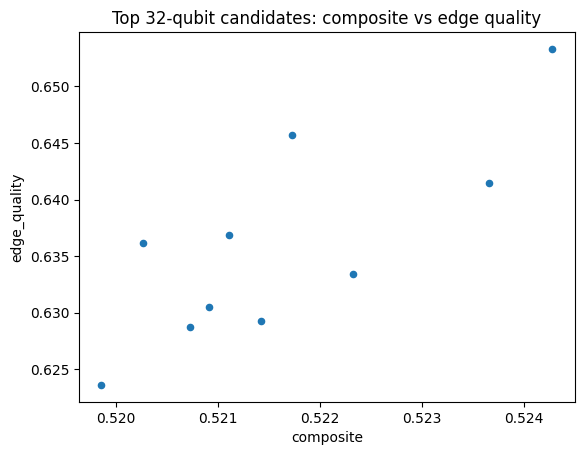

In [7]:
# ---------- Part 5: Recommended 32-qubit region ----------
metrics32 = region_metrics(FINAL32)
sub32 = G.subgraph(FINAL32)

print("Recommended 32-qubit region:")
print(list(FINAL32))
print("\nValidation:")
print("Number of qubits:", len(FINAL32))
print("Connected:", nx.is_connected(sub32))
print("Uncalibrated internal edges:", metrics32["has_uncalibrated_edge"])
print("Internal edges:", metrics32["internal_edges"])

summary32 = pd.DataFrame([metrics32]).drop(columns=["size", "connected", "has_uncalibrated_edge"])
display(summary32.T.rename(columns={0: "32-qubit value"}))

baseline32 = random_connected_baseline(32, 300, 202)
comparison32 = pd.DataFrame({
    "Selected region": [
        metrics32["composite"], metrics32["qubit_quality"],
        metrics32["edge_quality"], metrics32["robustness"]
    ],
    "Random baseline mean": [
        baseline32["composite"].mean(), baseline32["qubit_quality"].mean(),
        baseline32["edge_quality"].mean(), baseline32["robustness"].mean()
    ]
}, index=["Composite", "Qubit quality", "Edge quality", "Robustness"])
display(comparison32)

ax = candidates32.head(10).plot(
    x="composite", y="edge_quality", kind="scatter",
    title="Top 32-qubit candidates: composite vs edge quality"
)
plt.show()

## Recommendation Notes

Both recommendations are physically connected and contain no uncalibrated internal CZ edges. The selected regions were compared with multiple alternative connected candidates and with randomly grown connected baselines of the same size.

The 16-qubit recommendation is the more compact choice when a smaller, consistently reliable region is sufficient. The 32-qubit recommendation provides a larger connected working area while accepting the normal trade-off that a larger region has more opportunities to include weaker components.

### Recommendation Rationale

The recommendations were not produced by ranking individual qubits independently. Instead, the topology constrained the search so every candidate was a connected hardware region. The final score gives the largest importance to two-qubit connection quality because multi-qubit jobs depend strongly on coupler reliability. Qubit-level quality and bottleneck robustness receive equal secondary emphasis, while connectivity rewards regions with better internal routing structure.

The robustness term is important because a region with a good mean can still fail to be attractive if it contains one very poor qubit or coupler.

### Additional Information

Confidence would improve with calibration history over multiple days/runs, workload-specific benchmark results, gate-direction details, crosstalk measurements, simultaneous-operation effects and application-specific circuit requirements. A single calibration snapshot is useful for a point-in-time recommendation, but time-series stability would show whether the selected regions remain strong consistently.

In [8]:
# ---------- Final validation ----------
assert len(FINAL16) == 16
assert len(FINAL32) == 32
assert nx.is_connected(G.subgraph(FINAL16))
assert nx.is_connected(G.subgraph(FINAL32))
assert not region_metrics(FINAL16)["has_uncalibrated_edge"]
assert not region_metrics(FINAL32)["has_uncalibrated_edge"]

print("FINAL VALIDATION PASSED")
print("16-qubit region:", list(FINAL16))
print("32-qubit region:", list(FINAL32))

FINAL VALIDATION PASSED
16-qubit region: [87, 97, 103, 104, 105, 106, 107, 108, 109, 117, 118, 124, 125, 126, 128, 129]
32-qubit region: [39, 52, 53, 54, 55, 59, 73, 74, 75, 79, 87, 89, 90, 91, 92, 93, 94, 95, 97, 98, 103, 104, 105, 106, 107, 108, 109, 110, 111, 117, 125, 126]
